In [36]:
import numpy as np
import pandas as pd 
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import matplotlib.pyplot as plt 
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, ConfusionMatrixDisplay
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [4]:
df = pd.read_csv(r"C:\Users\DELL\OneDrive\Documents\Deep Learning\titanic-train.csv")
print(df.head(3))
print("Dataset shape:", df.shape)
print(df.info())
print(df.isnull().sum())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
Dataset shape: (891, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    in

In [15]:
#feature selection
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
X = df[features].copy()
y = df["Survived"].copy()

In [6]:
print("input shape:", X.shape)
print("output shape:", y.shape)
print("\nSurvival counts:")
print(y.value_counts())

input shape: (891, 7)
output shape: (891,)

Survival counts:
Survived
0    549
1    342
Name: count, dtype: int64


In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [16]:
numerical_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]

In [17]:
numeric_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='median')), ('standard', StandardScaler())])

numerical transformer process categorical features. Suppose the training ages are20, 25, missing, 35, and 40. The median of the non-missing values is 30, so the missing age is filled with 30


In [18]:
categorical_features = ["Sex", "Embarked"]

In [19]:
categorical_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')), ('onehot',OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
))])

An ANN cannot directly process a text value such as male and female. One hot Encoding converts categories into numerical indicator columns. 
For example:    Sex       Female   male
                female      1       0
                male        0        1
The encoder creates the actual columns from the categories it learns during training. The number of processed features will therefore be greater than the original seven columns. 
handle_unknown="ignore"

If a new category appears during prediction that wasn't present during training, the encoder can handle it without failing. 

sparse_output=False is supported by newer scikit-learn versions. if you use an older version that rejects this argument, replace it with sparse=false. 

In [20]:
#Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[('num', numeric_transformer, numerical_features), 
                                               ('cat', categorical_transformer, categorical_features)], 
                                              verbose_feature_names_out=False)

In [24]:
X_train_processed = preprocessor.fit_transform(X_train)

In [25]:
X_test_processed = preprocessor.transform(X_test)

In [26]:
print(X_train_processed)

[[-1.61413602  1.25364106 -0.47072241 ...  0.          0.
   1.        ]
 [-0.40055118 -0.47728355 -0.47072241 ...  0.          0.
   1.        ]
 [ 0.81303367  0.21508629 -0.47072241 ...  0.          0.
   1.        ]
 ...
 [ 0.81303367  0.90745614  1.23056874 ...  0.          0.
   1.        ]
 [-1.61413602 -1.1696534   0.37992316 ...  0.          0.
   1.        ]
 [-1.61413602 -0.63114352 -0.47072241 ...  0.          0.
   1.        ]]


In [27]:
model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

The output layer remains a single sigmoid neuron because survival has two possible outcomes:
 i. 0 = did not survive
 ii. 1 = survived

In [28]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 897 (3.50 KB)

 Trainable params: 897 (3.50 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

In [31]:
early_stopping = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

restore_best_weights restores weights from the epochs with the best validation loss

In [32]:
history = model.fit(X_train_processed, y_train, epochs=100, batch_size=32, validation_split=0.20, callbacks=[early_stopping], verbose=1)

Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.3884 - loss: 0.7410 - val_accuracy: 0.3846 - val_loss: 0.7150
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5308 - loss: 0.6927 - val_accuracy: 0.6783 - val_loss: 0.6650
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6274 - loss: 0.6558 - val_accuracy: 0.7133 - val_loss: 0.6312
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6960 - loss: 0.6236 - val_accuracy: 0.7133 - val_loss: 0.6017
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6872 - loss: 0.6045 - val_accuracy: 0.7133 - val_loss: 0.5754
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7206 - loss: 0.5812 - val_accuracy: 0.7273 - val_loss: 0.5509
Epoch 7/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7135 - loss: 0.5664 - val_accuracy: 0.7483 - val_loss: 0.5254
Epoch 8/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7434 - loss: 0.5290 - val_accuracy: 0.7902 

In [33]:
#Predict survival probabilities
y_prob = model.predict(X_test_processed)
y_pred = (y_prob>0.5).astype(int).ravel()   #Convert probabilities into 0/1 predictions

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


In [34]:
print("Test Accuracy:", accuracy_score(y_test, y_pred))

Test Accuracy: 0.8100558659217877


In [35]:
print("\nClassification Report")
print(classification_report(y_test, y_pred))


Classification Report
              precision    recall  f1-score   support

           0       0.82      0.87      0.84       105
           1       0.79      0.73      0.76        74

    accuracy                           0.81       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179



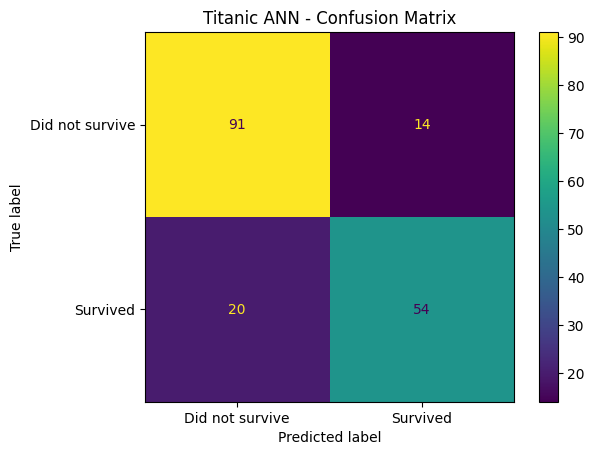

In [37]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Did not survive", "Survived"])
disp.plot()
plt.title("Titanic ANN - Confusion Matrix")
plt.show()

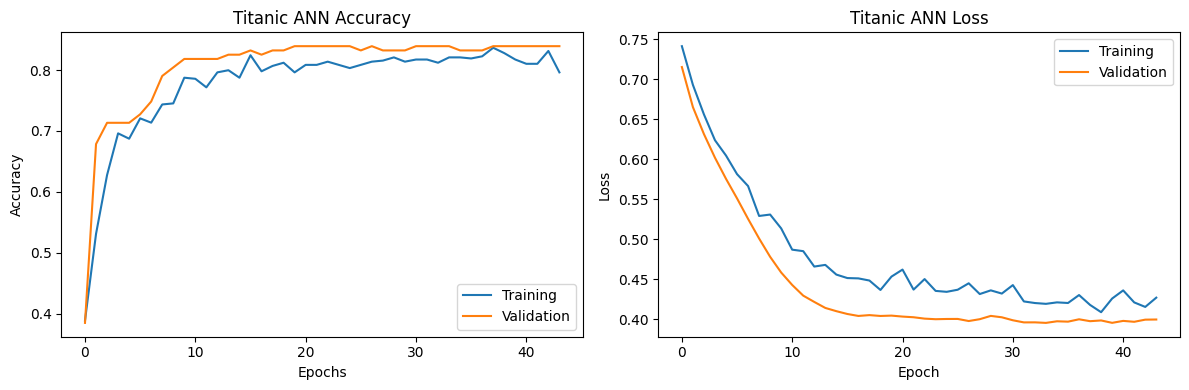

In [38]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Titanic ANN Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Titanic ANN Loss")
plt.legend()

plt.tight_layout()
plt.show()

restore_best_weights=True := Restores weights from the epoch with the best validation loss.

epochs=100 := Maximum of 100 passes tnrough the training portions. 

batch_size=32 := Processed up to 32 training records per batch.

validation_split=0.20 := Holds out 20% of the supplied training data for validation. 

callbacks = [early_stopping] := Stops if validation loss fails to improve for 10 epochs. 